# PA-S1. Продуктовая аналитика автострахования

**Индивидуальный проект, трек Б.**  
**Автор:** Грмаш Артём Александрович.  
**Группа:** ИУ6-71Б.  
**Тема:** удержание страховых договоров и финансовые показатели портфеля автомобилей в Испании за 2022–2024 годы.

**Источник:** *A detailed dataset of motor insurance policies with coverage-specific financial information*, Mendeley Data, версия 1 (2026).  
https://data.mendeley.com/datasets/sw4jmdb2sm/1

В работе я рассматриваю страхование автомобилей как продукт с оформлением, обслуживанием и продлением полиса. Важно: публичный датасет описывает **страховые договоры**, а не клики пользователя в приложении. Единица анализа — `insured_id` (ID полиса). Поэтому я рассчитываю годовое удержание **активных договоров**, а не месячный retention физических лиц.

**Репозиторий:** https://github.com/AreyomGarmash/product-analytics

## 1. Продукт и задача

Я рассматриваю условный цифровой сервис автострахования: клиент выбирает покрытие, оформляет полис, получает информацию по страховым случаям и продлевает договор.

**Кому нужен продукт:** владельцам автомобилей, которые покупают или продлевают страховку. Доступные срезы для анализа — возраст водителя и автомобиля, тип покрытия и территория.

**Проблема:** компания теряет часть действующих договоров при продлении. При этом удерживать клиентов любой ценой невыгодно: важно следить за выплатами и убыточностью.

**Продуктовая гипотеза:** в дальнейшем напоминания и более понятное предложение для продления могли бы улучшить удержание без роста убыточности. **Проверить эффект напоминаний по этому файлу нельзя**, потому что в нём нет отправленных уведомлений и экспериментов.

**Бизнес-модель:** доход от страховых премий; существенная часть затрат — страховые случаи (включая зарезервированные суммы), также существуют другие расходы компании, которых в датасете нет.

**Цель этой сдачи:** проверить пригодность данных, сформулировать метрики и получить исходные значения удержания и финансовых показателей.

## 2. Источник и данные

Датасет взят с [Mendeley Data](https://data.mendeley.com/datasets/sw4jmdb2sm/1), версия 1. Публикация содержит анонимизированные реальные данные испанского автомобильного страхования за 2022–2024 годы. Авторы: **Priscila Espinosa, Josep Lledó, David Atance**. DOI: **10.17632/sw4jmdb2sm.1**. Лицензия — **CC BY 4.0**; при использовании нужно указать авторов, название работы, источник и лицензию.

Файлы проекта:

- `data/Dataset of motor insurance portfolio.csv.gz` — основная таблица;
- `data/Descriptive of variables.xlsx` — описание переменных от авторов.

CSV загружается по относительному пути. Гранулярность — **одна запись на страховой полис в календарном году**, а не журнал ежедневных событий. Точные даты оплаты или действий клиента отсутствуют. Это главное ограничение для заданий по продуктовой аналитике.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('data') / 'Dataset of motor insurance portfolio.csv.gz'
assert DATA_PATH.exists(), f'Нет файла {DATA_PATH}. См. README.md'
df = pd.read_csv(DATA_PATH, sep=';', low_memory=False)
assert {'insured_id','year','policy_status','business_type','total_premium','total_incurred','total_claims'}.issubset(df.columns)
print(f'Строк: {len(df):,}; столбцов: {len(df.columns)}; ID договоров: {df.insured_id.nunique():,}')
display(df.head(5))

Строк: 354,140; столбцов: 47; ID договоров: 185,678


,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,fuel_type,vehicle_value,seats,power_to_weight_ratio,vehicle_brand,municipality_type,circulation_area,total_premium,liability_premium,property_damage_premium,theft_premium,fire_premium,glass_premium,legal_protection_premium,occupants_premium,total_claims,liability_claims,liability_property_claims,liability_injury_claims,property_claims,theft_claims,fire_claims,glass_claims,legal_protection_claims,occupants_claims,total_incurred,liability_incurred,liability_property_incurred,liability_injury_incurred,property_incurred,theft_incurred,fire_incurred,glass_incurred,legal_protection_incurred,occupants_incurred,total_exposure,liability_exposure
0,1,2022,COMP_E,C,NB,A,G,48,22.0,26.0,G,149511.4425,4,3.92,PORSCHE,I,U,279.557558,30.602324,121.912690,112.361489,3.832441,8.305788,2.043622,0.499205,0,0,0,0,0,0,0,0,0,0,0.0000,0.000,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.09863,0.09863
1,2,2022,COMP_E,A,P,A,G,43,24.0,19.0,D,65065.1232,8,10.15,MERCEDES,I,U,546.623415,114.333356,303.105967,80.784824,7.826861,30.091751,7.812747,2.667908,0,0,0,0,0,0,0,0,0,0,0.0000,0.000,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
2,2,2023,COMP_E,A,P,A,G,44,25.0,19.0,D,65065.1232,8,10.15,MERCEDES,I,U,548.752558,110.666891,304.955990,83.521384,6.151465,32.861626,7.655637,2.939566,1,1,1,0,0,0,0,0,0,0,233.0130,233.013,233.013,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
3,2,2024,COMP_E,A,P,A,G,45,26.0,18.0,D,65065.1232,8,10.15,MERCEDES,I,U,584.632430,122.092532,305.225093,107.886872,5.842892,31.101584,10.084173,2.399283,2,1,1,0,1,0,0,0,0,0,2586.3615,1035.000,1035.000,0.0,1551.3615,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
4,3,2022,COMP_E,A,NB,S,G,45,26.0,19.0,D,51626.6625,7,9.19,KIA,I,R,687.490508,214.583989,354.874140,53.077620,7.715765,48.574298,6.700701,1.963995,0,0,0,0,0,0,0,0,0,0,0.0000,0.000,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000


## 3. Проверка качества и ограничений данных

Проверяю пропуски, дубли по `insured_id` + `year`, диапазон лет, невалидные идентификаторы и необычные финансовые значения. Выбросы не удаляю автоматически: крупный страховой убыток может быть реальным.

В словаре переменных `insured_id` определяется как ID страхового **полиса**, повторяющийся между годами. Отдельного ID физического лица нет. Тестовые записи нельзя достоверно выделить — соответствующего признака в наборе нет.

Дополнительно проверяю нулевую экспозицию: у такого договора за год могла отсутствовать фактическая продолжительность страхования.

In [2]:
quality = pd.DataFrame({
    'missing_n': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(3),
    'unique_values': df.nunique(dropna=True),
})
display(quality.sort_values('missing_n', ascending=False).head(12))

print('Полные дубли:', int(df.duplicated().sum()))
print('Дубли по insured_id + year:', int(df.duplicated(['insured_id', 'year']).sum()))
print('Годы:', sorted(df.year.unique().tolist()))
print('ID <= 0:', int((df.insured_id <= 0).sum()))
print('Премия <= 0:', int((df.total_premium <= 0).sum()))
print('Экспозиция <= 0:', int((df.total_exposure <= 0).sum()))
print('Отрицательные убытки:', int((df.total_incurred < 0).sum()))
print('Отменённые договоры (строки C):', int(df.policy_status.eq('C').sum()))

display(df[['total_premium', 'total_incurred', 'total_claims', 'total_exposure']]
        .describe(percentiles=[.01, .5, .95, .99]).T.round(2))
assert df['year'].isin([2022, 2023, 2024]).all()
assert not df.duplicated(['insured_id', 'year']).any()


,missing_n,missing_pct,unique_values
fuel_type,1287,0.363,2
vehicle_value,513,0.145,13494
age_driving_licence,2,0.001,71
vehicle_age,2,0.001,68
insured_id,0,0.000,185678
year,0,0.000,3
policy_type,0,0.000,5
bonus_score,0,0.000,3
payment_frequency,0,0.000,3
business_type,0,0.000,2


Полные дубли: 0
Дубли по insured_id + year: 0
Годы: [2022, 2023, 2024]
ID <= 0: 0
Премия <= 0: 49
Экспозиция <= 0: 49
Отрицательные убытки: 0
Отменённые договоры (строки C): 38328


,count,mean,std,min,1%,50%,95%,99%,max
total_premium,354140.0,296.72,227.85,0.0,6.72,257.90,704.53,1086.90,5107.64
total_incurred,354140.0,208.58,2274.71,0.0,0.00,0.00,1055.30,3784.28,571128.32
total_claims,354140.0,0.22,0.66,0.0,0.00,0.00,1.00,3.00,18.00
total_exposure,354140.0,0.71,0.33,0.0,0.02,0.84,1.00,1.00,1.00


In [3]:
year_table = df.groupby('year').agg(
    records=('insured_id','size'), unique_policies=('insured_id','nunique'),
    premium=('total_premium','sum'), incurred=('total_incurred','sum'),
    cancelled=('policy_status',lambda s:s.eq('C').sum())
)
year_table['cancellation_share_pct'] = (100*year_table.cancelled/year_table.records).round(2)
year_table['avg_premium_active'] = df.loc[df.policy_status.eq('A')].groupby('year').total_premium.mean().round(2)
year_table['loss_ratio_pct'] = (100*year_table.incurred/year_table.premium).round(2)
display(year_table.round(2))

,records,unique_policies,premium,incurred,cancelled,cancellation_share_pct,avg_premium_active,loss_ratio_pct
year,,,,,,,,
2022,67172,67172,18697928.34,12270105.06,4064,6.05,273.45,65.62
2023,118835,118835,35344308.08,23488354.35,13480,11.34,302.98,66.46
2024,168133,168133,51037433.00,38106351.28,20784,12.36,313.69,74.66


**Что заметно по проверке.** Пропусков мало: больше всего в `fuel_type` (1 287 строк, 0,363%) и `vehicle_value` (513, 0,145%). Дублей по `insured_id` + `year` нет. У 49 строк одновременно нулевая премия и нулевая экспозиция; все они имеют статус отмены. Их нельзя автоматически считать ошибкой — это могут быть реальные отменённые договоры. Максимальный убыток сильно превышает типичную премию: для страхования это ожидаемый риск, а не обязательный дефект данных.

**Первое наблюдение:** доля строк со статусом отмены увеличилась с 6,05% в 2022 году до 12,36% в 2024-м, а Loss Ratio — с 65,62% до 74,66%. Это сравнение состава портфеля по годам; оно **не доказывает**, что один и тот же клиент стал уходить чаще.

## 4. Определения метрик

Определения фиксирую до дальнейших расчётов.

| Метрика | Как считаю | Что нельзя утверждать |
|---|---|---|
| **Активный договор** | Строка за год со статусом `policy_status = 'A'` | Это не активный пользователь приложения |
| **Когорта** | Год первого появления `insured_id` в файле; в знаменатель retention беру полисы, **активные в этом первом году** | Первый год в файле не обязательно год первичного оформления |
| **Retention Y+1** | Доля активных договоров базового года, сохранивших статус `A` в следующем году | Это годовое удержание договоров, не помесячный retention клиентов |
| **Отмена** | `policy_status='C'` в текущем году | Доля отменённых строк не равна вероятности оттока на фиксированной когорте |
| **Конверсия в оформление** | Число оформленных договоров / число посетителей, увидевших предложение | **Не рассчитывается:** в файле нет визитов и показов предложения; `business_type='NB'` не заменяет эту метрику |
| **Премии** | `sum(total_premium)` | Начисленная премия — не подтверждённая отдельная платёжная транзакция |
| **Loss Ratio** | `sum(total_incurred) / sum(total_premium)` | Не учитывает все операционные расходы |
| **Исторический вклад** | `sum(total_premium - total_incurred)` за доступные годы | Не является полным LTV; будущие годы неизвестны |
| **CAC** | Расходы на привлечение / число новых клиентов | **Не рассчитывается:** нет рекламных расходов и отдельных клиентских ID |

Если договор встречается в следующем году со статусом `C`, его **нельзя** считать удержанным. Ниже отдельно показываю, как это влияет на результат.

## 5. Пирамида метрик: что измеряем и зачем

| Уровень | Метрика | Решение по результатам |
|---|---|---|
| **North Star** | Годовой retention **активных** договоров (`A → A`) | Найти сегменты с проблемами продления и проверить гипотезы удержания |
| Диагностическая 1 | Доля отменённых записей (`policy_status='C'`) по годам и типам полисов | Где сосредоточены отмены; не путать с когортным retention |
| Диагностическая 2 | Средняя премия на активный полис | Оценить ценовую структуру и различия сегментов |
| **Риск** | Loss Ratio | Не предлагать удержание убыточных сегментов без проверки экономики |

Сама по себе корреляция между размером премии и удержанием не доказывает, что снижение цены увеличит продления.

## 6. План трекинга

Для трека Б нужно не менее трёх событий. В файле нет логов сайта, поэтому первые четыре пункта — **реконструкция бизнес-событий из годовых записей**, а не настоящие клиентские события с точным временем. Последний пункт предлагаю для будущего трекинга.

| Событие | Триггер | Параметры | Метрика | Этап пути | Поле в датасете |
|---|---|---|---|---|---|
| `policy_registered_in_year` | Договор присутствует в годовой выгрузке | `insured_id`, `year`, `business_type` | База договоров, когорты | Оформление/обслуживание | `insured_id`, `year`, `business_type` |
| `policy_status_recorded` | Зафиксирован статус договора | `insured_id`, `year`, `policy_status` | Retention, отмены | Продление/отток | `policy_status`, `year` |
| `premium_recorded` | В годовой строке есть начисленная премия | `insured_id`, `year`, `total_premium` | Премия, финансовый вклад | Монетизация | `total_premium`, `year` |
| `claim_summary_recorded` | За год указаны убытки и число случаев | `insured_id`, `year`, `total_claims`, `total_incurred` | Loss Ratio | Использование страховки | `total_claims`, `total_incurred` |
| `renewal_reminder_sent` (план) | Сервис отправил напоминание о продлении | `policy_id`, `sent_at`, `channel` | Эффект коммуникаций | Удержание | **Нет; потребуется новая система событий** |

Если появятся логи приложения, нужно добавить реальные события `quote_viewed`, `quote_accepted`, `payment_completed` и точные временные метки.

## 7. Когортный retention активных договоров

Когорта — год первого появления ID в датасете. В исходную численность когорты включаю только договоры со статусом `A` в этот год. Далее считаю, сколько из них имеют статус `A` в каждом следующем году.

Это отличается от простой проверки «ID встречается в следующем году»: запись со статусом `C` означает отмену и не должна попадать в числитель удержания. Для 2024→2025 вычисления нет — файл заканчивается в 2024 году.

Активных полисов при входе в когорту:


,active_cohort_size
cohort_year,
2022,63108
2023,54828
2024,61849


Retention активных полисов, %:


year,2022,2023,2024
cohort_year,,,
2022,100.0,80.06,66.18
2023,NaN,100.00,79.77
2024,NaN,NaN,100.00


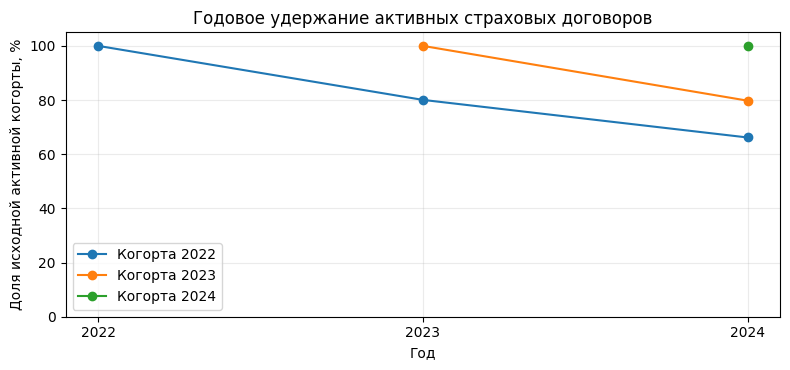

In [4]:
# Дата появления договора доступна только с точностью до года.
first_year = df.groupby('insured_id')['year'].min().rename('cohort_year')
with_cohorts = df.join(first_year, on='insured_id')
cohort_base = with_cohorts.loc[
    with_cohorts.year.eq(with_cohorts.cohort_year) & with_cohorts.policy_status.eq('A'),
    ['insured_id', 'cohort_year']
].drop_duplicates()
active_years = df.loc[df.policy_status.eq('A'), ['insured_id', 'year']].drop_duplicates()
retained = cohort_base.merge(active_years, on='insured_id', how='left')

cohort_sizes = cohort_base.groupby('cohort_year')['insured_id'].nunique()
active_counts = retained.groupby(['cohort_year', 'year'])['insured_id'].nunique().unstack(fill_value=0)
cohort_retention = (active_counts.div(cohort_sizes, axis=0) * 100).round(2)
cohort_retention = cohort_retention.where(
    cohort_retention.columns.to_numpy()[None, :] >= cohort_retention.index.to_numpy()[:, None]
)
print('Активных полисов при входе в когорту:')
display(cohort_sizes.rename('active_cohort_size').to_frame())
print('Retention активных полисов, %:')
display(cohort_retention)

fig, ax = plt.subplots(figsize=(8, 3.8))
for y in cohort_retention.index:
    s = cohort_retention.loc[y].dropna()
    ax.plot(s.index.astype(str), s, marker='o', label=f'Когорта {y}')
ax.set_ylim(0, 105)
ax.set_ylabel('Доля исходной активной когорты, %')
ax.set_xlabel('Год')
ax.set_title('Годовое удержание активных страховых договоров')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


In [5]:
# Сравниваем договоры со статусом A в соседних годах.
active = df.loc[df.policy_status.eq('A'), ['insured_id', 'year']].drop_duplicates()
base = active.loc[active.year < 2024].copy()
next_active = active.rename(columns={'year': 'next_year'}).copy()
next_active['year'] = next_active.next_year - 1
next_active['active_next_year'] = True
compare = base.merge(next_active[['insured_id', 'year', 'active_next_year']],
                     on=['insured_id', 'year'], how='left')
compare['active_next_year'] = compare['active_next_year'].eq(True)
annual_retention = compare.groupby('year').agg(
    active_policies=('insured_id', 'nunique'),
    retained_active=('active_next_year', 'sum'),
)
annual_retention['retention_pct'] = (
    100 * annual_retention.retained_active / annual_retention.active_policies
).round(2)
display(annual_retention)

# Покажем, насколько завышается результат, если учитывать все присутствующие ID, включая C.
all_years = df[['insured_id', 'year']].drop_duplicates()
next_any = all_years.rename(columns={'year': 'next_year'}).copy()
next_any['year'] = next_any.next_year - 1
next_any['present_next_year'] = True
any_return = all_years[all_years.year < 2024].merge(
    next_any[['insured_id', 'year', 'present_next_year']],
    on=['insured_id', 'year'], how='left'
)
raw_presence = any_return.groupby('year').present_next_year.count()
raw_base = any_return.groupby('year').insured_id.nunique()
comparison = pd.DataFrame({
    'Любое присутствие в следующем году, %': (100 * raw_presence / raw_base).round(2),
    'Активный договор A → A, %': annual_retention.retention_pct,
})
display(comparison)


,active_policies,retained_active,retention_pct
year,,,
2022,63108,50527,80.06
2023,105355,85500,81.15


,"Любое присутствие в следующем году, %","Активный договор A → A, %"
year,,
2022,93.95,80.06
2023,88.66,81.15


**Интерпретация:** из 63 108 активных договоров 2022 года активными в 2023 году остались 50 527 (80,06%). Для активных договоров 2023 года удержание в 2024-м — 81,15%. Если проверять только наличие ID в следующем году, получаются завышенные 93,95% и 88,66%, потому что часть полисов уже отмечена как отменённая. Поэтому в выводах использую только `A → A`. В когортах процент считается от **активных в первый наблюдаемый год**, а не от всех строк.

## 8. LTV / CAC и доступные финансовые метрики

По PA-S1 для трека Б нужны **retention и LTV/CAC**. Но у нас нет расходов на рекламу и привлечения, отдельного ID клиента и истории платежей с датами. Следовательно, **настоящий CAC, LTV и отношение LTV/CAC из этих полей не получить**. Это ограничение нужно согласовать с преподавателем; я не подставляю условные суммы и не называю их фактическими данными.

Вместо этого рассчитываю показатели, которые можно проверить на источнике:

- начисленные премии (`total_premium`);
- понесённые страховые убытки с резервами (`total_incurred`);
- Loss Ratio;
- исторический вклад страхового полиса до прочих расходов (премии минус убытки).

Исторический вклад — полезная оценка, но **не LTV**: данных за всю жизнь полиса и остальных затрат нет.

In [6]:
policy_finance = df.groupby('insured_id', as_index=False).agg(
    observed_years=('year','nunique'),
    premium_total=('total_premium','sum'),
    incurred_total=('total_incurred','sum'))
policy_finance['contribution_observed'] = policy_finance.premium_total-policy_finance.incurred_total
summary = pd.Series({
    'Полисы (ID)': len(policy_finance),
    'Сумма премий': df.total_premium.sum(),
    'Сумма incurred': df.total_incurred.sum(),
    'Loss Ratio, %': 100*df.total_incurred.sum()/df.total_premium.sum(),
    'Сумма наблюдаемого вклада': policy_finance.contribution_observed.sum(),
    'Средний наблюдаемый вклад на ID': policy_finance.contribution_observed.mean(),
    'Истинный CAC': np.nan,
    'LTV/CAC': np.nan,
})
display(summary.to_frame('Значение').round(2))
print('CAC и LTV/CAC = NaN: расходных данных по привлечению нет. Это ограничение, а не нулевой CAC.')
display(policy_finance[['premium_total','incurred_total','contribution_observed']].describe(percentiles=[.5,.9,.99]).round(2))

,Значение
Полисы (ID),1.856780e+05
Сумма премий,1.050797e+08
Сумма incurred,7.386481e+07
"Loss Ratio, %",7.029000e+01
Сумма наблюдаемого вклада,3.121486e+07
Средний наблюдаемый вклад на ID,1.681100e+02
Истинный CAC,NaN
LTV/CAC,NaN


CAC и LTV/CAC = NaN: расходных данных по привлечению нет. Это ограничение, а не нулевой CAC.


,premium_total,incurred_total,contribution_observed
count,185678.00,185678.00,185678.00
mean,565.92,397.81,168.11
std,523.13,3165.42,3153.63
min,0.00,0.00,-571077.99
50%,432.63,0.00,317.07
90%,1183.04,1012.00,984.93
99%,2436.57,6626.10,2025.53
max,14558.08,571128.32,14558.08


**Интерпретация:** сумма премий за три года составляет около 105,08 млн условных денежных единиц, а Loss Ratio — **70,29%**. Исторический вклад портфеля до прочих затрат — около 31,21 млн; средний на один ID полиса — **168,11** за наблюдаемый период. Это **не прогнозный LTV**: полисы наблюдаются разное число лет, а распределение убытков сильно скошено. Единица валюты в рабочем CSV не указана, поэтому ниже не приписываю суммам валюту без проверки документации.

### Выбросы в финансовых показателях

Страховые убытки распределены неравномерно: небольшое число крупных случаев сильно влияет на среднее. Поэтому ниже показываю распределения с ограниченными осями **только для визуализации**. В расчёте Loss Ratio и финансового вклада суммы остаются исходными.

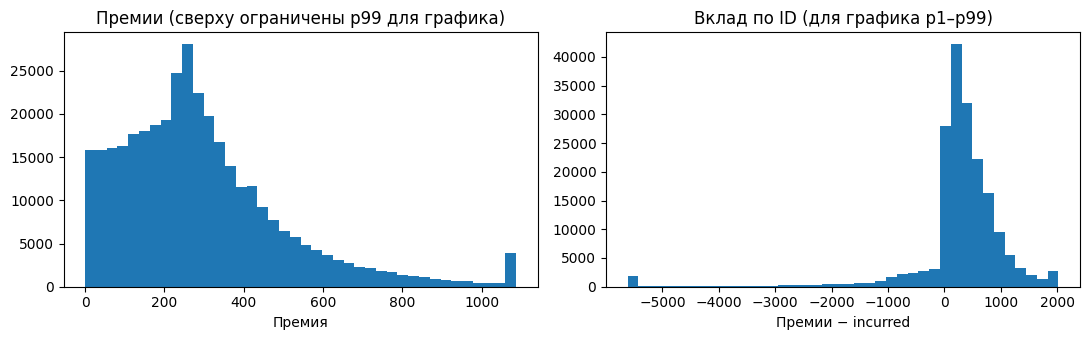

Договоров с отрицательным наблюдаемым вкладом: 21914


In [7]:
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].hist(df.total_premium.clip(upper=df.total_premium.quantile(.99)),bins=40)
axs[0].set_title('Премии (сверху ограничены p99 для графика)');axs[0].set_xlabel('Премия')
axs[1].hist(policy_finance.contribution_observed.clip(lower=policy_finance.contribution_observed.quantile(.01),upper=policy_finance.contribution_observed.quantile(.99)),bins=40)
axs[1].set_title('Вклад по ID (для графика p1–p99)');axs[1].set_xlabel('Премии − incurred')
plt.tight_layout();plt.show()
print('Договоров с отрицательным наблюдаемым вкладом:',int(policy_finance.contribution_observed.lt(0).sum()))

## 9. Этика (краткий комментарий для трека Б)

Использую данные только для учебного исследования, не для автоматического решения, кому отказать в страховке. Датасет опубликован в обезличенном виде, но возраст водителя, территория и характеристики машины всё равно создают риск косвенной идентификации в маленьких группах. Поэтому не публикую таблицы с отдельными полисами и не пытаюсь восстановить личности.

В статье авторы указывают, что согласие было получено страховой компанией при оформлении продукта; **проверить согласие по самим строкам нельзя**. Раскрывать данные третьим лицам и загружать их в сторонние сервисы без необходимости не планирую. Локальные копии при завершении проекта можно удалить. При публикации соблюдаю CC BY 4.0 и даю ссылку на источник.

Возраст, география и история выплат используются для исследовательских срезов, а не для дискриминационных автоматических решений.

## 10. Критерии успеха и проверка

**Базовые значения по датасету:** годовое удержание `A → A` составляет 80,06% и 81,15%, общий Loss Ratio — 70,29%. На основе этих значений формулирую ориентиры для дальнейшего анализа:

| Метрика | Целевое значение к концу проекта | Как проверить |
|---|---|---|
| Retention `A → A` | Обосновать сегменты, в которых удержание не ниже **82%** (выше общей базы около 80–81%) | Посчитать удержание по сегментам, проверить численность и устойчивость на двух переходах между годами |
| Loss Ratio | Для выбранных сегментов удержания держать Loss Ratio **ниже 75%** | Рассчитать сумму убытков / сумму премий, исключить выводы по малым группам |
| Модель отмены | ROC-AUC **не ниже 0,60** на отложенном периоде | Обучить по признакам 2022 → статус 2023, проверить признаки 2023 → статус 2024, сравнить с ROC-AUC случайного baseline = 0,50 |

Это **цели проекта и критерии выбора сегментов**, а не доказанные изменения продукта. Для проверки реального повышения удержания после изменений сервиса понадобятся данные нового периода и эксперимент.

## 11. Выводы и ограничения

По исходным данным видно, что страховой портфель большой, а убыточность нельзя игнорировать даже при хороших показателях удержания. Для меня самый интересный следующий вопрос — **в каких сегментах чаще теряются активные договоры и отличается ли убыточность этих сегментов от остальных**.

Основные ограничения, которые нужно учитывать при защите:

1. `insured_id` — ID полиса, а не клиента. Нельзя называть расчёт удержанием уникальных людей.
2. Время записано только по годам. Нет даты регистрации, оплаты, пользовательского события; DAU и месячный retention не посчитать.
3. Премии — не таблица транзакций, а `total_incurred` включает резервы и не равен всем расходам страховщика.
4. Нет маркетингового бюджета: CAC и LTV/CAC **не определены**.
5. В файле нет 2025 года, поэтому удержание за 2024→2025 неизвестно.
6. Данные очищены авторами; осталось небольшое число пропусков, выбросы возможны, тестовые строки отдельно не помечены.

**Перед сдачей необходимо согласовать с преподавателем** использование годовых статусов полиса вместо ежедневного журнала событий и замену LTV/CAC доступными показателями. В PA-S1 отдельно указано, что отсутствие данных для LTV/CAC нужно фиксировать и согласовывать.

## 12. Подготовка к сдаче

Проверено в работе:

- [x] Продуктовая гипотеза, аудитория и бизнес-модель
- [x] Источник, описание переменных и аудит качества
- [x] Определения активного договора, когорт и удержания
- [x] North Star + 2 диагностические метрики + риск-метрика
- [x] План трекинга с привязкой к полям (годовые бизнес-события)
- [x] Расчёт когортного retention активных полисов и финансовых показателей
- [x] Этика, критерии успеха и ограничения

Что остаётся сделать **самостоятельно перед отправкой**:

- [x] Указаны ФИО и группа автора в начале ноутбука.
- [x] Указана ссылка на личный репозиторий.
- [ ] Согласовать с преподавателем отсутствие дневных событий и LTV/CAC.
- [ ] Загрузить все файлы в репозиторий, включая сжатый CSV (`.csv.gz`).
- [ ] Ещё раз запустить **Run All** после загрузки проекта в репозиторий и быть готовым объяснить расчёты.

**Запуск:** `python -m pip install -r requirements.txt`, затем `jupyter notebook PA_S1_Motor_Insurance.ipynb` из папки проекта.